In [2]:
import pandas as pd
import numpy as np

df = pd.read_csv("Dataset .csv")
df["Cuisines"] = df["Cuisines"].fillna("Unknown")

print(df.shape)
df.head()

(9551, 21)


,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",...,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",...,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229


In [3]:
df["Primary Cuisine"] = df["Cuisines"].apply(lambda x: x.split(",")[0].strip())

TOP_N = 10
top_cuisines = df["Primary Cuisine"].value_counts().nlargest(TOP_N).index
df = df[df["Primary Cuisine"].isin(top_cuisines)].copy()

print(f"Restricted to top {TOP_N} cuisines -> {len(df)} restaurants remain")
print(df["Primary Cuisine"].value_counts())

Restricted to top 10 cuisines -> 7014 restaurants remain
Primary Cuisine
North Indian    2992
Chinese          855
Fast Food        672
Bakery           621
Cafe             617
American         278
South Indian     262
Mithai           246
Street Food      236
Continental      235
Name: count, dtype: int64


In [4]:
from sklearn.preprocessing import LabelEncoder

for col in ["Has Table booking", "Has Online delivery"]:
    df[col] = df[col].map({"Yes": 1, "No": 0})

le_city = LabelEncoder()
df["City Encoded"] = le_city.fit_transform(df["City"])

df["Cuisine Count"] = df["Cuisines"].apply(lambda x: len(x.split(",")))

le_target = LabelEncoder()
y = le_target.fit_transform(df["Primary Cuisine"])

features = ["Average Cost for two", "Price range", "Votes", "Aggregate rating",
            "Has Table booking", "Has Online delivery", "Cuisine Count", "City Encoded"]
X = df[features]

print(X.shape, y.shape)

(7014, 8) (7014,)


In [5]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f"Train: {X_train.shape}, Test: {X_test.shape}")

Train: (5611, 8), Test: (1403, 8)


In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42, max_depth=12),
}

for name, model in models.items():
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    acc = accuracy_score(y_test, preds)
    prec = precision_score(y_test, preds, average="weighted", zero_division=0)
    rec = recall_score(y_test, preds, average="weighted", zero_division=0)
    f1 = f1_score(y_test, preds, average="weighted", zero_division=0)
    print(f"{name:20s} | Acc: {acc:.4f} | Precision: {prec:.4f} | Recall: {rec:.4f} | F1: {f1:.4f}")

c:\Users\vijua\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Logistic Regression  | Acc: 0.4348 | Precision: 0.2750 | Recall: 0.4348 | F1: 0.3028
Random Forest        | Acc: 0.4918 | Precision: 0.4429 | Recall: 0.4918 | F1: 0.4203


              precision    recall  f1-score   support

    American       0.76      0.66      0.70        56
      Bakery       0.35      0.18      0.24       124
        Cafe       0.45      0.32      0.37       123
     Chinese       0.19      0.04      0.07       171
 Continental       0.29      0.04      0.07        47
   Fast Food       0.32      0.15      0.20       135
      Mithai       0.48      0.41      0.44        49
North Indian       0.52      0.88      0.65       599
South Indian       0.75      0.06      0.11        52
 Street Food       0.39      0.30      0.34        47

    accuracy                           0.49      1403
   macro avg       0.45      0.30      0.32      1403
weighted avg       0.44      0.49      0.42      1403



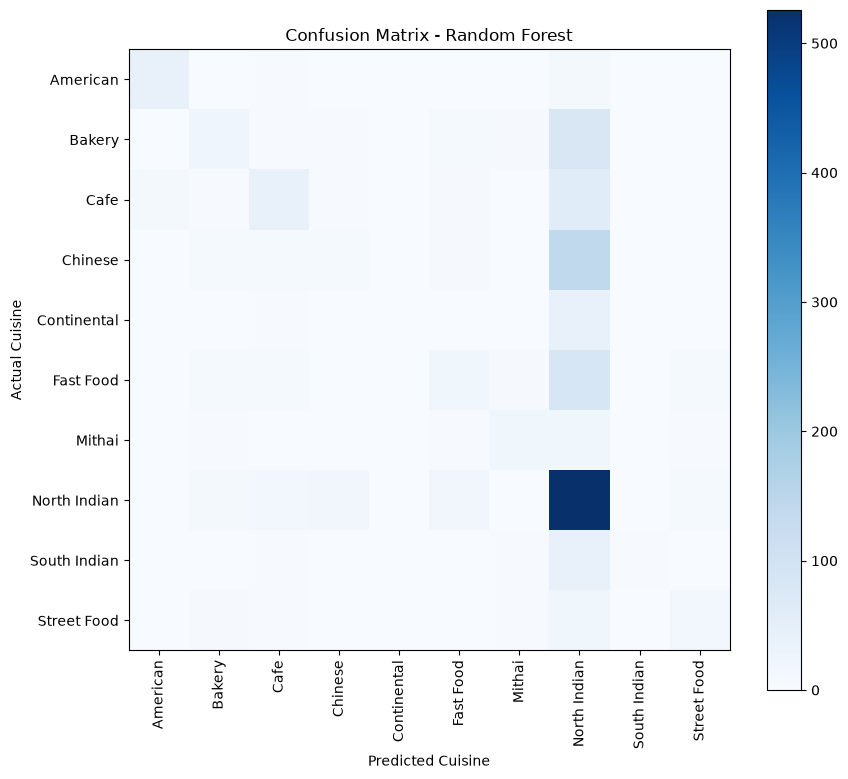

In [7]:
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix

rf = models["Random Forest"]
preds = rf.predict(X_test)

print(classification_report(y_test, preds, target_names=le_target.classes_, zero_division=0))

cm = confusion_matrix(y_test, preds)
plt.figure(figsize=(9, 8))
plt.imshow(cm, cmap="Blues")
plt.colorbar()
plt.xticks(range(len(le_target.classes_)), le_target.classes_, rotation=90)
plt.yticks(range(len(le_target.classes_)), le_target.classes_)
plt.xlabel("Predicted Cuisine")
plt.ylabel("Actual Cuisine")
plt.title("Confusion Matrix - Random Forest")
plt.tight_layout()
plt.show()